In [1]:

# Step 1: Import Libraries

# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train and test split
from sklearn.model_selection import train_test_split

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Step 2: Load Dataset

from google.colab import files

uploaded = files.upload()


Saving weather-anomalies-1964-2013.csv to weather-anomalies-1964-2013.csv


In [3]:
df = pd.read_csv("weather-anomalies-1964-2013.csv")

In [4]:

import pandas as pd

df = pd.read_csv("/content/weather-anomalies-1964-2013.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [5]:

# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check dataset information
print("\nDataset Information:")
df.info()


Dataset Shape: (3196832, 10)

Column Names:
Index(['date_str', 'degrees_from_mean', 'id', 'longitude', 'latitude',
       'max_temp', 'min_temp', 'station_name', 'type', 'serialid'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3196832 entries, 0 to 3196831
Data columns (total 10 columns):
 #   Column             Dtype  
---  ------             -----  
 0   date_str           object 
 1   degrees_from_mean  float64
 2   id                 object 
 3   longitude          float64
 4   latitude           float64
 5   max_temp           float64
 6   min_temp           float64
 7   station_name       object 
 8   type               object 
 9   serialid           int64  
dtypes: float64(5), int64(1), object(4)
memory usage: 243.9+ MB


In [6]:

# Check missing values in each column

print(df.isnull().sum())


date_str             0
degrees_from_mean    0
id                   0
longitude            0
latitude             0
max_temp             0
min_temp             0
station_name         0
type                 0
serialid             0
dtype: int64


In [7]:

# Statistical summary

df.describe()


,degrees_from_mean,longitude,latitude,max_temp,min_temp,serialid
count,3.196832e+06,3.196832e+06,3.196832e+06,3.196832e+06,3.196832e+06,3.196832e+06
mean,-2.012912e-01,-9.781747e+01,3.928314e+01,1.855650e+01,5.600244e+00,1.598416e+06
std,1.461818e+01,1.738886e+01,6.431866e+00,1.469611e+01,1.400033e+01,9.228461e+05
min,-1.031800e+02,-1.702222e+02,1.348360e+01,-5.440000e+01,-5.500000e+01,1.000000e+00
25%,-1.132000e+01,-1.094847e+02,3.498940e+01,1.000000e+01,-2.200000e+00,7.992088e+05
50%,5.480000e+00,-9.597500e+01,3.950920e+01,2.110000e+01,7.800000e+00,1.598416e+06
75%,1.076000e+01,-8.514830e+01,4.357640e+01,3.000000e+01,1.670000e+01,2.397624e+06
max,3.487500e+02,1.447961e+02,7.128330e+01,5.440000e+01,3.822000e+02,3.196832e+06


In [8]:
# Count each category

print(df['type'].value_counts())

type
Weak Hot       1555771
Weak Cold      1209162
Strong Cold     223065
Strong Hot      208834
Name: count, dtype: int64


In [9]:
# Display first 10 dates

print(df['date_str'].head(10))

0    1977-02-19
1    1977-02-19
2    1977-02-19
3    1977-02-19
4    1977-02-19
5    1977-02-19
6    1977-02-19
7    1977-02-19
8    1977-02-19
9    1977-02-19
Name: date_str, dtype: object


In [10]:
# Check inconsistent temperature records

print("Inconsistent records:",
      (df['min_temp'] > df['max_temp']).sum())

Inconsistent records: 9153


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
# Convert date column into datetime

df['date_str'] = pd.to_datetime(df['date_str'])

# Check data type

print(df['date_str'].dtype)

datetime64[ns]


In [13]:
# Extract date features

df['year'] = df['date_str'].dt.year
df['month'] = df['date_str'].dt.month
df['day'] = df['date_str'].dt.day

# Display results

df[['date_str', 'year', 'month', 'day']].head()

,date_str,year,month,day
0,1977-02-19,1977,2,19
1,1977-02-19,1977,2,19
2,1977-02-19,1977,2,19
3,1977-02-19,1977,2,19
4,1977-02-19,1977,2,19


In [14]:
# Find inconsistent temperature records

invalid_rows = df[df['min_temp'] > df['max_temp']]

# Display first 10 records

invalid_rows[['date_str', 'min_temp', 'max_temp',
              'station_name']].head(10)

,date_str,min_temp,max_temp,station_name
70868,1964-07-18,65.6,36.1,BIG BAR 4 E
71040,1964-07-19,65.6,31.7,BIG BAR 4 E
71135,1964-07-16,66.1,31.1,BIG BAR 4 E
71273,1964-07-17,68.3,35.6,BIG BAR 4 E
71474,1964-07-14,69.4,39.4,BIG BAR 4 E
71568,1964-07-15,71.7,29.4,BIG BAR 4 E
71762,1964-07-12,72.2,42.2,BIG BAR 4 E
72138,1964-07-13,73.3,42.8,BIG BAR 4 E
72341,1964-07-11,66.7,39.4,BIG BAR 4 E
73725,1964-04-30,7.2,6.1,WINONA 5 E


In [15]:
print("Total inconsistent records:", len(invalid_rows))

print("Percentage of inconsistent records:",
      round((len(invalid_rows) / len(df)) * 100, 2), "%")

Total inconsistent records: 9153
Percentage of inconsistent records: 0.29 %


In [16]:
# Display 10 inconsistent records

print(invalid_rows[
    ['date_str', 'max_temp', 'min_temp',
     'station_name', 'type']
].head(10).to_string(index=False))

  date_str  max_temp  min_temp station_name      type
1964-07-18      36.1      65.6  BIG BAR 4 E  Weak Hot
1964-07-19      31.7      65.6  BIG BAR 4 E  Weak Hot
1964-07-16      31.1      66.1  BIG BAR 4 E  Weak Hot
1964-07-17      35.6      68.3  BIG BAR 4 E  Weak Hot
1964-07-14      39.4      69.4  BIG BAR 4 E  Weak Hot
1964-07-15      29.4      71.7  BIG BAR 4 E  Weak Hot
1964-07-12      42.2      72.2  BIG BAR 4 E  Weak Hot
1964-07-13      42.8      73.3  BIG BAR 4 E  Weak Hot
1964-07-11      39.4      66.7  BIG BAR 4 E  Weak Hot
1964-04-30       6.1       7.2   WINONA 5 E Weak Cold


In [17]:

# Step 1: Check maximum temperature statistics

print("Maximum Temperature Statistics:")
print(df['max_temp'].describe())

# Step 2: Check minimum temperature statistics

print("\nMinimum Temperature Statistics:")
print(df['min_temp'].describe())

# Step 3: Find inconsistent temperature records

invalid_rows = df[df['min_temp'] > df['max_temp']]

print("\nInconsistent Temperature Records:",
      len(invalid_rows))

# Step 4: Display examples

print("\nFirst 10 Inconsistent Records:")

print(invalid_rows[
    ['date_str', 'min_temp', 'max_temp', 'station_name']
].head(10))


Maximum Temperature Statistics:
count    3.196832e+06
mean     1.855650e+01
std      1.469611e+01
min     -5.440000e+01
25%      1.000000e+01
50%      2.110000e+01
75%      3.000000e+01
max      5.440000e+01
Name: max_temp, dtype: float64

Minimum Temperature Statistics:
count    3.196832e+06
mean     5.600244e+00
std      1.400033e+01
min     -5.500000e+01
25%     -2.200000e+00
50%      7.800000e+00
75%      1.670000e+01
max      3.822000e+02
Name: min_temp, dtype: float64

Inconsistent Temperature Records: 9153

First 10 Inconsistent Records:
        date_str  min_temp  max_temp station_name
70868 1964-07-18      65.6      36.1  BIG BAR 4 E
71040 1964-07-19      65.6      31.7  BIG BAR 4 E
71135 1964-07-16      66.1      31.1  BIG BAR 4 E
71273 1964-07-17      68.3      35.6  BIG BAR 4 E
71474 1964-07-14      69.4      39.4  BIG BAR 4 E
71568 1964-07-15      71.7      29.4  BIG BAR 4 E
71762 1964-07-12      72.2      42.2  BIG BAR 4 E
72138 1964-07-13      73.3      42.8  BIG BAR 4 E

In [18]:

# Find minimum temperatures greater than 60

suspicious_rows = df[df['min_temp'] > 60]

print("Suspicious records:", len(suspicious_rows))

# Display first 10 records

print(suspicious_rows[
    ['date_str', 'min_temp', 'max_temp', 'station_name']
].head(10))

# Display the highest value

print("\nHighest minimum temperature:",
      df['min_temp'].max())


Suspicious records: 37
         date_str  min_temp  max_temp            station_name
70868  1964-07-18      65.6      36.1             BIG BAR 4 E
71040  1964-07-19      65.6      31.7             BIG BAR 4 E
71135  1964-07-16      66.1      31.1             BIG BAR 4 E
71273  1964-07-17      68.3      35.6             BIG BAR 4 E
71474  1964-07-14      69.4      39.4             BIG BAR 4 E
71568  1964-07-15      71.7      29.4             BIG BAR 4 E
71762  1964-07-12      72.2      42.2             BIG BAR 4 E
72138  1964-07-13      73.3      42.8             BIG BAR 4 E
72341  1964-07-11      66.7      39.4             BIG BAR 4 E
101189 1964-06-25     179.4      23.3  BLUEFIELD MERCER CO AP

Highest minimum temperature: 382.2


In [19]:
# Remove inconsistent temperature records

df_clean = df[df['min_temp'] <= df['max_temp']].copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

# Check again
print("Remaining inconsistent records:",
      (df_clean['min_temp'] > df_clean['max_temp']).sum())

Original dataset: (3196832, 13)
Cleaned dataset: (3187679, 13)
Remaining inconsistent records: 0


In [20]:
print("Maximum Temperature:")
print(df_clean['max_temp'].describe())

print("\nMinimum Temperature:")
print(df_clean['min_temp'].describe())

# Find unusually high minimum temperatures
high_temp = df_clean[df_clean['min_temp'] > 60]

print("\nRecords with minimum temperature above 60:")
print(len(high_temp))

print(high_temp[
    ['date_str', 'min_temp', 'max_temp', 'station_name']
].head(10))

Maximum Temperature:
count    3.187679e+06
mean     1.859992e+01
std      1.467497e+01
min     -5.220000e+01
25%      1.000000e+01
50%      2.110000e+01
75%      3.000000e+01
max      5.440000e+01
Name: max_temp, dtype: float64

Minimum Temperature:
count    3.187679e+06
mean     5.577432e+00
std      1.398462e+01
min     -5.500000e+01
25%     -2.200000e+00
50%      7.800000e+00
75%      1.670000e+01
max      4.500000e+01
Name: min_temp, dtype: float64

Records with minimum temperature above 60:
0
Empty DataFrame
Columns: [date_str, min_temp, max_temp, station_name]
Index: []


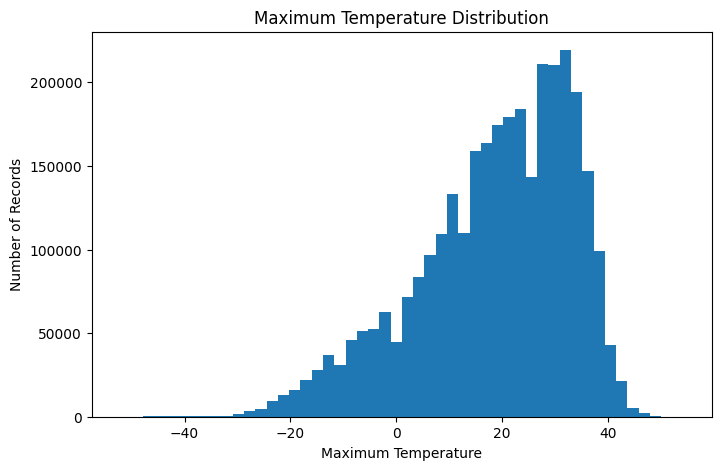

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df_clean['max_temp'], bins=50)

plt.title('Maximum Temperature Distribution')
plt.xlabel('Maximum Temperature')
plt.ylabel('Number of Records')

plt.show()

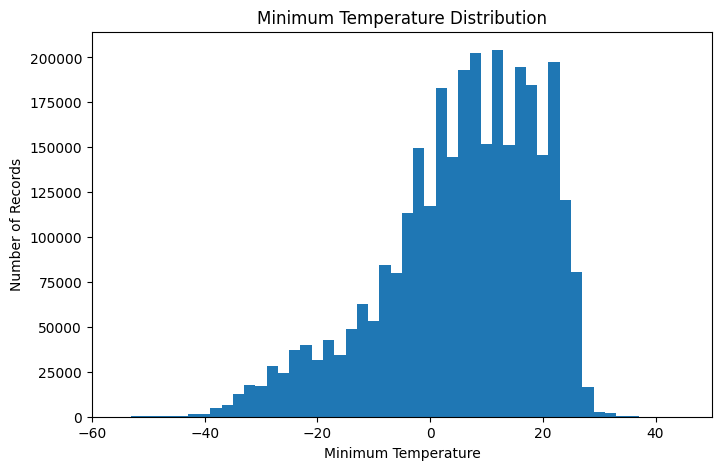

In [22]:
plt.figure(figsize=(8, 5))

plt.hist(df_clean['min_temp'], bins=50)

plt.title('Minimum Temperature Distribution')
plt.xlabel('Minimum Temperature')
plt.ylabel('Number of Records')

plt.show()

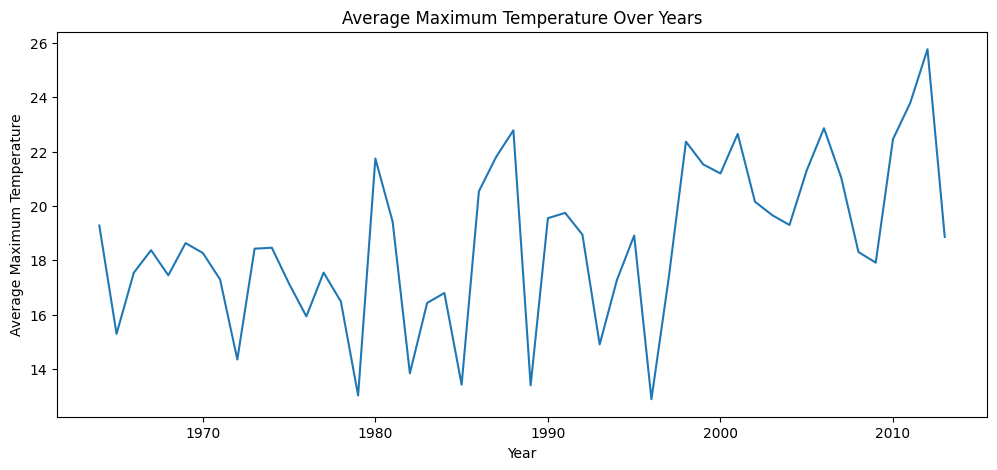

In [23]:
yearly_temp = df_clean.groupby('year')['max_temp'].mean()

plt.figure(figsize=(12, 5))

plt.plot(yearly_temp.index, yearly_temp.values)

plt.title('Average Maximum Temperature Over Years')
plt.xlabel('Year')
plt.ylabel('Average Maximum Temperature')

plt.show()

In [24]:
# Select input features
X = df_clean[
    ['min_temp', 'latitude', 'longitude',
     'year', 'month', 'day']
]

# Select target
y = df_clean['max_temp']

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Input features:
   min_temp  latitude  longitude  year  month  day
0     -12.8   43.7186  -113.5472  1977      2   19
1      -8.9   37.7717  -107.1097  1977      2   19
2      12.8   37.0919  -119.5128  1977      2   19
3      -3.9   33.4783  -109.7517  1977      2   19
4      13.9   33.8089  -115.4508  1977      2   19

Target values:
0    10.0
1    11.1
2    25.6
3    20.0
4    30.6
Name: max_temp, dtype: float64

Input shape: (3187679, 6)
Target shape: (3187679,)


In [25]:
# Sort data by date
df_model = df_clean.sort_values('date_str').copy()

# Select input features
X = df_model[
    ['min_temp', 'latitude', 'longitude',
     'year', 'month', 'day']
]

# Select target
y = df_model['max_temp']

# Calculate 80% split
split_index = int(len(df_model) * 0.80)

# Training data
X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

# Testing data
X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

# Display results
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining date range:")
print(df_model['date_str'].iloc[0],
      "to", df_model['date_str'].iloc[split_index - 1])

print("\nTesting date range:")
print(df_model['date_str'].iloc[split_index],
      "to", df_model['date_str'].iloc[-1])

Training data: (2550143, 6)
Testing data: (637536, 6)

Training target: (2550143,)
Testing target: (637536,)

Training date range:
1964-01-01 00:00:00 to 2003-07-23 00:00:00

Testing date range:
2003-07-23 00:00:00 to 2013-12-31 00:00:00


In [26]:
# Get all unique dates
unique_dates = df_model['date_str'].drop_duplicates().sort_values()

# Find the date at the 80% position
split_date = unique_dates.iloc[int(len(unique_dates) * 0.80)]

# Training data: dates before split date
train_data = df_model[df_model['date_str'] < split_date]

# Testing data: split date and later
test_data = df_model[df_model['date_str'] >= split_date]

# Select input features
X_train = train_data[
    ['min_temp', 'latitude', 'longitude',
     'year', 'month', 'day']
]

X_test = test_data[
    ['min_temp', 'latitude', 'longitude',
     'year', 'month', 'day']
]

# Select target
y_train = train_data['max_temp']
y_test = test_data['max_temp']

print("Split date:", split_date)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining dates:",
      train_data['date_str'].min(),
      "to", train_data['date_str'].max())

print("\nTesting dates:",
      test_data['date_str'].min(),
      "to", test_data['date_str'].max())

Split date: 2004-01-01 00:00:00
Training data: (2576230, 6)
Testing data: (611449, 6)

Training dates: 1964-01-01 00:00:00 to 2003-12-31 00:00:00

Testing dates: 2004-01-01 00:00:00 to 2013-12-31 00:00:00


In [27]:
from sklearn.linear_model import LinearRegression

# Create the model
model_lr = LinearRegression()

print("Linear Regression model created successfully!")

Linear Regression model created successfully!


In [28]:
# Train the model using training data
model_lr.fit(X_train, y_train)

print("Linear Regression Model Training Completed!")

Linear Regression Model Training Completed!


In [29]:
# Predict maximum temperature
y_pred_lr = model_lr.predict(X_test)

# Display first 10 predictions
print("Actual Temperatures:")
print(y_test.head(10).values)

print("\nPredicted Temperatures:")
print(y_pred_lr[:10])

Actual Temperatures:
[20.6 22.8 22.2 17.2 26.1  4.4 19.4  6.7 23.3 18.3]

Predicted Temperatures:
[26.52530246 22.70894566 12.1421174  23.26171392 35.88170462 10.78001704
 19.97853677 13.8997854  36.42275181 23.4964683 ]


In [30]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

In [31]:
# Calculate MAE
mae = mean_absolute_error(y_test, y_pred_lr)

# Calculate MSE
mse = mean_squared_error(y_test, y_pred_lr)

# Calculate RMSE
rmse = np.sqrt(mse)

# Calculate R2 Score
r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
-------------------------
MAE: 5.23536982893679
MSE: 40.74701277429623
RMSE: 6.383338685538801
R2 Score: 0.784854659205486


In [32]:
from sklearn.ensemble import RandomForestRegressor

# Select a sample for faster training
X_train_sample = X_train.sample(
    n=100000,
    random_state=42
)

y_train_sample = y_train.loc[X_train_sample.index]

# Create Random Forest model
model_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created!")

Random Forest model created!


In [33]:
model_rf.fit(X_train_sample, y_train_sample)

print("Random Forest training completed!")

Random Forest training completed!


In [34]:
# Predict maximum temperature
y_pred_rf = model_rf.predict(X_test)

# Display first 10 predictions
print("Actual Temperatures:")
print(y_test.head(10).values)

print("\nRandom Forest Predictions:")
print(y_pred_rf[:10])

Actual Temperatures:
[20.6 22.8 22.2 17.2 26.1  4.4 19.4  6.7 23.3 18.3]

Random Forest Predictions:
[23.5931648  25.44500938  8.88862855 25.70614248 27.09547252 11.67766592
 19.52148932 10.94074219 26.89190486 19.642366  ]


In [35]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae_rf = mean_absolute_error(y_test, y_pred_rf)

mse_rf = mean_squared_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Results
---------------------
MAE: 3.853137408209641
MSE: 26.272497548308174
RMSE: 5.125670448664074
R2 Score: 0.861280495091424


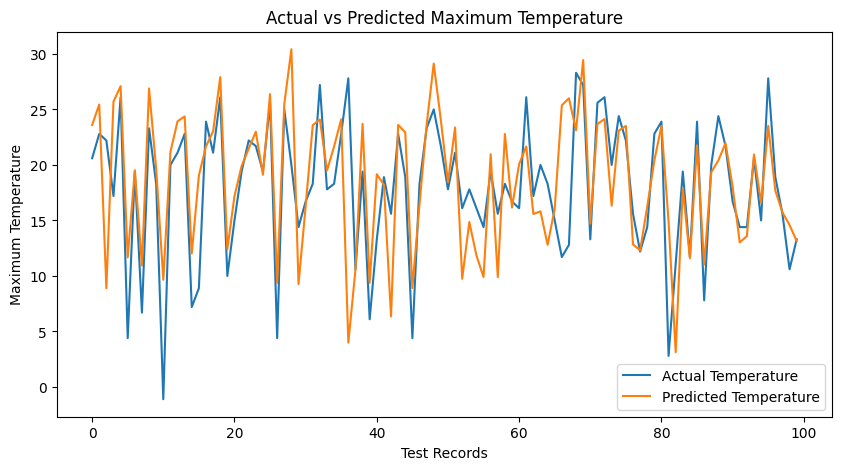

In [36]:
import matplotlib.pyplot as plt

# Select first 100 predictions
plt.figure(figsize=(10, 5))

plt.plot(y_test.iloc[:100].values, label='Actual Temperature')
plt.plot(y_pred_rf[:100], label='Predicted Temperature')

plt.title('Actual vs Predicted Maximum Temperature')
plt.xlabel('Test Records')
plt.ylabel('Maximum Temperature')

plt.legend()
plt.show()

In [37]:
# Select 10 testing examples
sample_data = X_test.iloc[:10]

# Actual temperatures
actual = y_test.iloc[:10].values

# Predicted temperatures
predicted = model_rf.predict(sample_data)

# Compare results
comparison = pd.DataFrame({
    'Actual Temperature': actual,
    'Predicted Temperature': predicted
})

comparison['Error'] = abs(
    comparison['Actual Temperature'] -
    comparison['Predicted Temperature']
)

print(comparison)

   Actual Temperature  Predicted Temperature      Error
0                20.6              23.593165   2.993165
1                22.8              25.445009   2.645009
2                22.2               8.888629  13.311371
3                17.2              25.706142   8.506142
4                26.1              27.095473   0.995473
5                 4.4              11.677666   7.277666
6                19.4              19.521489   0.121489
7                 6.7              10.940742   4.240742
8                23.3              26.891905   3.591905
9                18.3              19.642366   1.342366


In [38]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Predict test data
y_pred_rf = model_rf.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred_rf)

mse = mean_squared_error(y_test, y_pred_rf)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred_rf)

# Display results
print("Weather Prediction Model Performance")
print("------------------------------------")

print("R2 Score:", round(r2 * 100, 2), "%")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))

Weather Prediction Model Performance
------------------------------------
R2 Score: 86.13 %
MAE: 3.85
MSE: 26.27
RMSE: 5.13
